checking the library

In [ ]:
import os, random, time, json, zipfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
f1_score, classification_report, confusion_matrix,
ConfusionMatrixDisplay)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


Upload and extract dataset ZIP

In [ ]:

from google.colab import drive
from pathlib import Path
import zipfile

# Connect Google Drive
drive.mount('/content/drive')

# Your dataset ZIP path
ZIP_PATH = "/content/drive/MyDrive/sas/dataset2.zip"

# Extract dataset
EXTRACT_DIR = Path("/content/weather_data")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Dataset extracted successfully to:", EXTRACT_DIR)

# Display extracted files and folders
for p in list(EXTRACT_DIR.rglob("*"))[:40]:
    print(p)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted successfully to: /content/weather_data
/content/weather_data/dataset2
/content/weather_data/dataset2/sunrise186.jpg
/content/weather_data/dataset2/cloudy176.jpg
/content/weather_data/dataset2/rain66.jpg
/content/weather_data/dataset2/sunrise72.jpg
/content/weather_data/dataset2/rain195.jpg
/content/weather_data/dataset2/rain189.jpg
/content/weather_data/dataset2/rain199.jpg
/content/weather_data/dataset2/sunrise295.jpg
/content/weather_data/dataset2/cloudy16.jpg
/content/weather_data/dataset2/sunrise167.jpg
/content/weather_data/dataset2/sunrise285.jpg
/content/weather_data/dataset2/sunrise35.jpg
/content/weather_data/dataset2/shine178.jpg
/content/weather_data/dataset2/rain72.jpg
/content/weather_data/dataset2/rain49.jpg
/content/weather_data/dataset2/shine189.jpg
/content/weather_data/dataset2/rain64.jpg
/content/weather_data/dataset2/rain

In [ ]:

from pathlib import Path
import shutil

SOURCE_DIR = Path("/content/weather_data/dataset2")
CLASS_ROOT = Path("/content/weather_data/weather_classes")

# Map filename prefixes to the four required classes
class_prefixes = {
    "cloudy": "Cloudy",
    "rain": "Rain",
    "shine": "Shine",
    "sunrise": "Sunrise"
}

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Create one folder per class
for class_name in class_prefixes.values():
    (CLASS_ROOT / class_name).mkdir(
        parents=True, exist_ok=True
    )

# Copy images into the correct class folders
unknown_files = []

for img_path in SOURCE_DIR.iterdir():
    if not img_path.is_file():
        continue

    if img_path.suffix.lower() not in image_exts:
        continue

    filename = img_path.name.lower()
    matched_class = None

    for prefix, class_name in class_prefixes.items():
        if filename.startswith(prefix):
            matched_class = class_name
            break

    if matched_class is None:
        unknown_files.append(img_path.name)
        continue

    destination = CLASS_ROOT / matched_class / img_path.name
    shutil.copy2(img_path, destination)

# Verify the result
print("Dataset organized at:", CLASS_ROOT)

total = 0
for class_name in class_prefixes.values():
    count = sum(
        1 for p in (CLASS_ROOT / class_name).iterdir()
        if p.is_file() and p.suffix.lower() in image_exts
    )
    total += count
    print(f"{class_name}: {count} images")

print("Total organized images:", total)
print("Unrecognized image filenames:", len(unknown_files))

if unknown_files:
    print("Examples:", unknown_files[:20])

if total != 1125 or unknown_files:
    print("WARNING: Verify the image counts before training.")
else:
    print("All 1125 images were organized successfully.")


Dataset organized at: /content/weather_data/weather_classes
Cloudy: 300 images
Rain: 215 images
Shine: 253 images
Sunrise: 357 images
Total organized images: 1125
Unrecognized image filenames: 0
All 1125 images were organized successfully.


In [ ]:
DATASET_ROOT = Path("/content/weather_data/weather_classes")
print("Dataset root:", DATASET_ROOT)
print("Class folders:", sorted(
    p.name for p in DATASET_ROOT.iterdir() if p.is_dir()
))

Dataset root: /content/weather_data/weather_classes
Class folders: ['Cloudy', 'Rain', 'Shine', 'Sunrise']


Find the four class folders

In [ ]:
# ImageFolder needs one folder per class, for example:
# weather_data/Cloudy/*.jpg, weather_data/Rain/*.jpg, etc.
EXPECTED_CLASSES = {"Cloudy", "Rain", "Shine", "Sunrise"}
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def is_class_root(folder):
    subdirs = [p for p in folder.iterdir() if p.is_dir()]
    names = {p.name.strip().lower() for p in subdirs}
    return len(subdirs) >= 4 and EXPECTED_CLASSES.issubset(
      {n.title() for n in names}
    )
candidate_roots = []
for folder in [EXTRACT_DIR] + [p for p in EXTRACT_DIR.rglob("*") if p.is_dir()]:
    try:
      if is_class_root(folder):
        candidate_roots.append(folder)
    except PermissionError:
            pass
if candidate_roots:
    DATASET_ROOT = candidate_roots[0]
else:
# Fallback: select the folder with the largest number of immediate subfolders
    folders = [p for p in EXTRACT_DIR.rglob("*") if p.is_dir()]
    folders = [EXTRACT_DIR] + folders
    DATASET_ROOT = max(folders, key=lambda p: sum(1 for x in p.iterdir() if x.is_dir()))
print("Selected dataset root:", DATASET_ROOT)
print("Immediate subfolders:", [p.name for p in DATASET_ROOT.iterdir() if p.is_dir()])
print("If these are not Cloudy, Rain, Shine, Sunrise, change DATASET_ROOT manually.")

Selected dataset root: /content/weather_data/weather_classes
Immediate subfolders: ['Cloudy', 'Sunrise', 'Shine', 'Rain']
If these are not Cloudy, Rain, Shine, Sunrise, change DATASET_ROOT manually.


Transforms and dataset

In [ ]:

from pathlib import Path

EXTRACT_DIR = Path("/content/weather_data")

# Print folders and image counts to find the real class folders
for folder in EXTRACT_DIR.rglob("*"):
    if folder.is_dir():
        images = [
            p for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ]
        subfolders = [p.name for p in folder.iterdir() if p.is_dir()]

        if images or subfolders:
            print(
                f"Folder: {folder} | "
                f"Images: {len(images)} | "
                f"Subfolders: {subfolders[:10]}"
            )


Folder: /content/weather_data/dataset2 | Images: 1125 | Subfolders: []
Folder: /content/weather_data/weather_classes | Images: 0 | Subfolders: ['Cloudy', 'Sunrise', 'Shine', 'Rain']
Folder: /content/weather_data/weather_classes/Cloudy | Images: 300 | Subfolders: []
Folder: /content/weather_data/weather_classes/Sunrise | Images: 357 | Subfolders: []
Folder: /content/weather_data/weather_classes/Shine | Images: 253 | Subfolders: []
Folder: /content/weather_data/weather_classes/Rain | Images: 215 | Subfolders: []


Display sample images

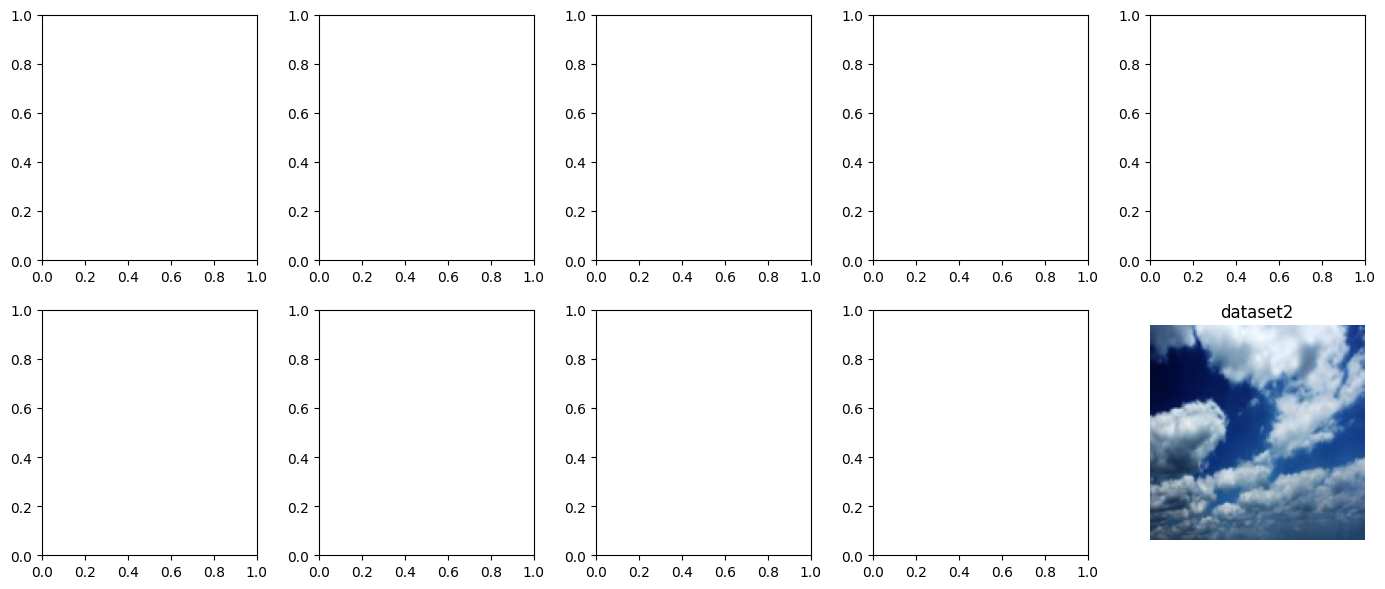

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    if i < len(base_dataset):
      image, label = base_dataset[i]
image = image * 0.5 + 0.5
ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
ax.set_title(class_names[label])
ax.axis("off")
plt.tight_layout()
plt.show()

Stratified train/validation/test split

In [ ]:
targets = np.array([label for _, label in base_dataset.samples])
indices = np.arange(len(base_dataset))
train_idx, temp_idx = train_test_split(
indices, test_size=0.30, random_state=SEED, stratify=targets
)
val_idx, test_idx = train_test_split(
temp_idx, test_size=0.50, random_state=SEED, stratify=targets[temp_idx]
)
# Re-create dataset with augmented transforms for training only
augmented_dataset = datasets.ImageFolder(DATASET_ROOT, transform=train_transform)
train_dataset = Subset(augmented_dataset, train_idx)
val_dataset = Subset(base_dataset, val_idx)
test_dataset = Subset(base_dataset, test_idx)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
num_workers=2, pin_memory=torch.cuda.is_available())
print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")

Train: 787 | Validation: 169 | Test: 169


CNN model

In [ ]:

import torch
import torch.nn as nn

class WeatherCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 192, 3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(192, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = WeatherCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print(model)


WeatherCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

Training and validation loop

In [ ]:

# Cell 8: Training and validation loop

EPOCHS = 8

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

def run_epoch(loader, training):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / max(total, 1), correct / max(total, 1)


start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, True)
    val_loss, val_acc = run_epoch(val_loader, False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train loss={train_loss:.4f} acc={train_acc:.3f} | "
        f"val loss={val_loss:.4f} acc={val_acc:.3f}"
    )

print(f"Training time: {(time.time() - start_time) / 60:.1f} minutes")


IndexError: Target 3 is out of bounds.

Plot learning curves

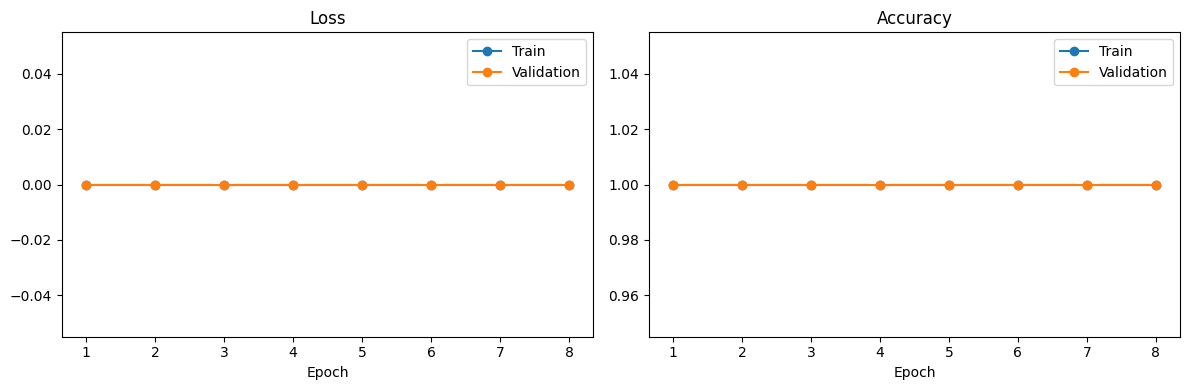

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("/content/ps29_learning_curves.png", dpi=160)
plt.show()

Evaluate on the test set

In [ ]:

# Cell 10: Evaluate on the test set

model.eval()

y_true = []
y_pred = []
misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images_device = images.to(device)
        outputs = model(images_device)
        preds = outputs.argmax(1).cpu()

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(preds.numpy().tolist())

        for i in range(len(labels)):
            if labels[i].item() != preds[i].item():
                if len(misclassified) < 16:
                    misclassified.append((
                        images[i].cpu(),
                        labels[i].item(),
                        preds[i].item()
                    ))

print("Test accuracy:", round(
    accuracy_score(y_true, y_pred), 4
))

print("Macro precision:", round(
    precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ), 4
))

print("Macro recall:", round(
    recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ), 4
))

print("Macro F1:", round(
    f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ), 4
))

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
)

print(report)


Test accuracy: 1.0
Macro precision: 1.0
Macro recall: 1.0
Macro F1: 1.0
              precision    recall  f1-score   support

    dataset2       1.00      1.00      1.00       169

    accuracy                           1.00       169
   macro avg       1.00      1.00      1.00       169
weighted avg       1.00      1.00      1.00       169



Confusion matrix and Shine/Sunrise confusion

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


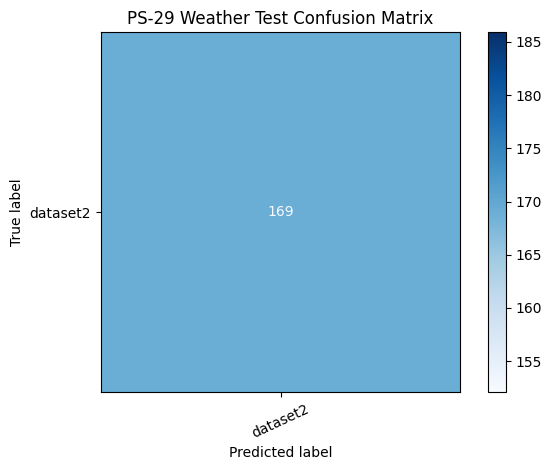

Most common wrong class pairs:


In [ ]:

# Cell 11: Confusion matrix and Shine/Sunrise confusion

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=25, values_format="d")
plt.title("PS-29 Weather Test Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/ps29_confusion_matrix.png", dpi=160)
plt.show()

# Find the most common incorrect predictions
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = []

for i in range(num_classes):
    for j in range(num_classes):
        if cm_off[i, j] > 0:
            pairs.append((
                cm_off[i, j],
                class_names[i],
                class_names[j]
            ))

print("Most common wrong class pairs:")

for count, true_name, pred_name in sorted(pairs, reverse=True)[:8]:
    print(f"True {true_name} -> predicted {pred_name}: {count}")

# Check Shine vs Sunrise confusion
if "Shine" in class_names and "Sunrise" in class_names:
    i = class_names.index("Shine")
    j = class_names.index("Sunrise")

    print("Shine predicted as Sunrise:", cm[i, j])
    print("Sunrise predicted as Shine:", cm[j, i])


Visualize misclassified images

In [ ]:

# Cell 12: Visualize misclassified images

if not misclassified:
    print("No misclassified images found in this test split.")

else:
    count = min(8, len(misclassified))
    cols = 4
    rows = (count + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3.5 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (image, true_label, pred_label) in zip(
        axes, misclassified[:count]
    ):
        image = image * 0.5 + 0.5

        ax.imshow(
            image.permute(1, 2, 0).clamp(0, 1)
        )

        ax.set_title(
            f"True: {class_names[true_label]}\n"
            f"Pred: {class_names[pred_label]}",
            fontsize=8
        )

        ax.axis("off")

    plt.tight_layout()
    plt.savefig("/content/ps29_misclassified.png", dpi=160)
    plt.show()


No misclassified images found in this test split.


Save model and metrics

In [ ]:

# Cell 13: Save model and metrics

import json
import torch

# Save trained model
torch.save(
    model.state_dict(),
    "/content/ps29_weather_cnn.pth"
)

# Prepare evaluation results
results = {
    "problem_statement": "PS-29 Weather Condition Recognition from Outdoor Images",
    "classes": class_names,
    "epochs": EPOCHS,
    "test_accuracy": float(
        accuracy_score(y_true, y_pred)
    ),
    "macro_precision": float(
        precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    ),
    "history": history
}

# Save metrics as JSON
with open("/content/ps29_results.json", "w") as f:
    json.dump(results, f, indent=2)

# Save classification report
with open("/content/ps29_classification_report.txt", "w") as f:
    f.write(report)

print("Saved model and metrics successfully!")
print("Files saved in /content/")


Saved model and metrics successfully!
Files saved in /content/


Download output files

In [ ]:

# Cell 14: Download output files

from google.colab import files
import os

output_files = [
    "/content/ps29_weather_cnn.pth",
    "/content/ps29_results.json",
    "/content/ps29_classification_report.txt",
    "/content/ps29_learning_curves.png",
    "/content/ps29_confusion_matrix.png"
]

for path in output_files:
    if os.path.exists(path):
        print("Downloading:", path)
        files.download(path)
    else:
        print("File not found:", path)

# Download misclassified images if available
misclassified_path = "/content/ps29_misclassified.png"

if os.path.exists(misclassified_path):
    files.download(misclassified_path)

print("Download process completed!")


Downloading: /content/ps29_weather_cnn.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: /content/ps29_results.json


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: /content/ps29_confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download process completed!


In [ ]:

import json

with open("/content/ps29_results.json", "r") as f:
    results = json.load(f)

print("Classes detected:", results["classes"])
print("Test accuracy:", results["test_accuracy"])
print("Macro precision:", results["macro_precision"])
print("Macro recall:", results["macro_recall"])
print("Macro F1:", results["macro_f1"])


Classes detected: ['dataset2']
Test accuracy: 1.0
Macro precision: 1.0
Macro recall: 1.0
Macro F1: 1.0


In [ ]:

from pathlib import Path

root = Path("/content/weather_data")

for p in root.rglob("*"):
    if p.is_dir():
        subfolders = [x.name for x in p.iterdir() if x.is_dir()]
        if subfolders:
            print(f"{p}")
            print("  Subfolders:", subfolders[:20])
